# 12 — RQ2: gom cụm review actionable bằng BERTopic, loại chủ đạo và type purity (Kaggle hoặc máy local)

**Đầu vào**

`actionable_reviews.csv` của notebook 11: mọi review của corpus Shopee mà cascade ViSoBERT (amendment v2.2) gọi ACTIONABLE, kèm nhãn
tầng 2 (BUG / FEATURE / UX).

**Gom chung rồi gắn loại**

Toàn bộ review actionable được gom trong một lần chạy (CLAUDE.md §1). Nhãn BUG / FEATURE / UX không dùng để chia dữ liệu trước khi
gom; nó được gắn vào cụm sau khi gom để xác định loại chủ đạo. Gom riêng từng loại là ablation tùy chọn, không làm ở đây.

**Quy trình (research_protocol, mục RQ2)**

Sentence embedding của văn bản gốc → UMAP → HDBSCAN → c-TF-IDF trên văn bản đã tách từ. Theo amendment v2.3, chỉ review có ít nhất 3
từ nội dung định hình cụm; review ngắn hơn được gắn vào cụm gần nhất sau đó. `min_topic_size` chọn trên lưới
{15, 20, 30, 50, 75} theo coherence C_v (Q12); cấu hình suy biến (một cụm chiếm quá 30% review đã gom, hoặc quá 100 cụm) bị loại.
Cấu hình thắng được giảm outlier và gộp các cụm gần trùng. Loại chủ đạo: một loại chiếm ít nhất 60% review của cụm, nếu không thì
`mixed` kèm cờ cho BA (Q14).

**Cấu hình**

Mọi tham số đọc từ `03_configs/dev/rq2_topics_dev_config.yaml`; sau khi duyệt cụm, cấu hình thắng được khóa sang `03_configs/frozen/`.

**Nơi chạy**

Trên Kaggle: mã nguồn được clone từ repository như notebook 11, thư viện gom cụm được cài ở cell đầu, đầu vào là output của notebook 11
(gắn làm input), kết quả ghi vào `/kaggle/working/rq2_topics/` để tải về `05_experiments/rq2_topics/`. Trên máy local: đầu vào và kết
quả nằm trong `05_experiments/rq2_topics/`. Đặt tên cụm bằng LLM chỉ chạy trên máy local, vì API key đọc từ `.env`.

In [1]:
import os, sys, json, datetime, subprocess, warnings
ON_KAGGLE = os.path.exists('/kaggle/input')
if ON_KAGGLE:
    from kaggle_secrets import UserSecretsClient
    REPO_URL = 'github.com/dnhphuong-05/kltn-vn-app-review-requirements.git'
    ROOT = '/kaggle/working/repo'
    token = UserSecretsClient().get_secret('GITHUB_TOKEN')
    if not os.path.exists(ROOT):
        r = subprocess.run(['git', 'clone', '-q', f'https://{token}@{REPO_URL}', ROOT], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError('git clone thất bại: ' + r.stderr.replace(token, '***'))
    subprocess.run(['git', '-C', ROOT, 'remote', 'set-url', 'origin', f'https://{REPO_URL}'], check=True)
    del token
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'bertopic==0.17.4', 'underthesea==9.5.0', 'umap-learn',
                    'hdbscan', 'gensim'], check=True)
else:
    ROOT = os.path.abspath('..')
import numpy as np, pandas as pd
sys.path.insert(0, os.path.join(ROOT, '02_src'))
from src.utils.seeds import set_seed
set_seed(42)
warnings.filterwarnings('ignore', category=FutureWarning)
import bertopic, sentence_transformers, umap, hdbscan, gensim, underthesea
from src.clustering import core as C
from src.utils.display import show as show_table
CFG = C.load_config(ROOT)
if ON_KAGGLE:
    def find_file(name, root='/kaggle/input'):
        hits = [os.path.join(d, name) for d, _, fs in os.walk(root) if name in fs]
        if not hits:
            raise FileNotFoundError(f'Không tìm thấy {name} trong {root} — gắn output của notebook 11 làm input')
        return hits[0]
    IN = {f: find_file(f) for f in ('actionable_reviews.csv', 'gd11_run_info.json')}
    RES = '/kaggle/working/rq2_topics'
else:
    RES = os.path.join(ROOT, '05_experiments', 'rq2_topics')
    IN = {f: os.path.join(RES, f) for f in ('actionable_reviews.csv', 'gd11_run_info.json')}
CACHE = os.path.join(RES, 'cache')
os.makedirs(RES, exist_ok=True)
COMMIT = subprocess.run(['git', '-C', ROOT, 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
VERSIONS = {m.__name__: getattr(m, '__version__', '?') for m in (bertopic, sentence_transformers, umap, gensim, underthesea)}
VERSIONS['hdbscan'] = __import__('importlib.metadata').metadata.version('hdbscan')
print('Ngày chạy:', datetime.date.today().strftime('%d/%m/%Y'), '| commit:', COMMIT)
print(VERSIONS)

Ngày chạy: 29/10/2026 | commit: b4652370ca55bb0881cae33b75e57cea9a829ffe
{'bertopic': '0.17.4', 'sentence_transformers': '6.2.0', 'umap': '0.5.12', 'gensim': '4.4.0', 'underthesea': '9.5.0', 'hdbscan': '0.8.44'}


## Dữ liệu

**Kiểm tra đầu vào**

Số review phải khớp `gd11_run_info.json`; mỗi review có đúng một nhãn tầng 2. Cột `split` cho biết review nào thuộc Train,
Validation, Hold-out hay focused set; mọi review đều được gom.

In [2]:
ACT = pd.read_csv(IN['actionable_reviews.csv'], encoding='utf-8-sig')
INFO11 = json.load(open(IN['gd11_run_info.json'], encoding='utf-8'))
assert len(ACT) == INFO11['n_actionable'] and ACT['review_id'].is_unique
assert set(ACT['tier2_label']) <= set(C.TYPES)
N = len(ACT)
print(f'Review actionable: {N:,}')
print('Theo nhãn tầng 2:', ACT['tier2_label'].value_counts().to_dict())
print('Theo tập:', ACT['split'].value_counts().to_dict())

Review actionable: 10,897
Theo nhãn tầng 2: {'BUG': 4639, 'UX': 3761, 'FEATURE': 2497}
Theo tập: {'none': 10120, 'train': 397, 'holdout': 199, 'focused': 115, 'validation': 66}


## Văn bản cho c-TF-IDF và coherence

**Tách từ**

underthesea tách từ và chuyển chữ thường; từ ghép được nối bằng "_" (ví dụ `giao_hàng`). Từ dừng (trong config, gồm tên app vì có mặt
ở gần như mọi review), token không có chữ cái và token ngắn hơn 2 ký tự bị bỏ. c-TF-IDF và C_v dùng chung các token này.

**Embedding không dùng văn bản đã lọc**

Sentence embedding tính trên văn bản gốc; văn bản đã lọc chỉ phục vụ việc mô tả cụm.

**Review ít thông tin (amendment v2.3)**

Review còn dưới 3 từ nội dung sau khi lọc từ dừng (ví dụ "bị lỗi k vào được" chỉ còn `lỗi`, `vào`) không tham gia fit BERTopic. Ở lần
chạy đầu, các review chung chung như vậy tự tạo thành một cụm gom tạp lớn nhất (21% review actionable, C_v thấp nhất). Chúng không bị
bỏ: sau khi có cụm, mỗi review ngắn được gắn vào cụm có tâm gần nhất nếu đủ gần (cùng ngưỡng với bước giảm outlier), nếu không thì là
outlier với lý do "ít thông tin".

In [3]:
SEG = C.segment(ACT['text'])
TOKENS = C.tokens_for_topics(SEG, CFG['stopwords'], CFG['vectorizer']['min_token_chars'])
DOCS = [' '.join(t) for t in TOKENS]
n_empty = sum(1 for t in TOKENS if not t)
print(f'Token / review (trung vị): {np.median([len(t) for t in TOKENS]):.0f} | review không còn token: {n_empty} ({n_empty / N:.1%})')
print('Số từ khác nhau:', len({w for t in TOKENS for w in t}))
INF = C.informative_mask(TOKENS, CFG['informative']['min_content_tokens'])
FIT = np.where(INF)[0]
DOCS_F, TOKENS_F = [DOCS[i] for i in FIT], [TOKENS[i] for i in FIT]
print(f"Review dùng để fit (≥ {CFG['informative']['min_content_tokens']} từ nội dung): {INF.sum():,} ({INF.mean():.1%}) | "
      f'review ngắn gắn sau: {(~INF).sum():,}')

Token / review (trung vị): 8 | review không còn token: 21 (0.2%)
Số từ khác nhau: 10165
Review dùng để fit (≥ 3 từ nội dung): 9,328 (85.6%) | review ngắn gắn sau: 1,569


## Sentence embedding (Q13)

**Mô hình chính**

`paraphrase-multilingual-mpnet-base-v2`, revision pin trong config. Embedding được lưu đệm trong `05_experiments/rq2_topics/cache/`
(không commit).

**So nhanh với một Vietnamese SBERT**

`keepitreal/vietnamese-sbert` (PhoBERT, nhận văn bản đã tách từ) được so với mô hình chính trên phần non-test — bỏ review thuộc
Hold-out và focused set, chỉ giữ review dùng để fit — ở cùng một `min_topic_size` (30): C_v, tỷ lệ outlier, số cụm và từ khóa của các cụm lớn nhất. Ứng viên
chỉ được xem là tốt hơn khi C_v cao hơn và không suy biến theo cùng tiêu chí với lưới Q12. Theo Q13, đổi mô hình phải ghi amendment
trước khi khóa cấu hình BERTopic; notebook giữ mô hình chính và chỉ báo kết quả so sánh.

In [4]:
EMB = C.embed(ACT['text'].astype(str).tolist(), ACT['review_id'], CFG['embedding'], CACHE, 'mpnet_actionable')
print('Embedding chính:', EMB.shape)

nt0 = ~ACT['split'].isin(['holdout', 'focused']).to_numpy()
cand_cfg = CFG['embedding_candidate']
EMB_C0 = C.embed([SEG[i] for i in np.where(nt0)[0]], ACT['review_id'][nt0], cand_cfg, CACHE, 'visbert_nontest')
nt = nt0 & INF
EMB_C = EMB_C0[INF[nt0]]
docs_nt = [DOCS[i] for i in np.where(nt)[0]]
tok_nt = [TOKENS[i] for i in np.where(nt)[0]]
mts_c = cand_cfg['compare_min_topic_size']
cmp_rows, cmp_words = [], {}
for name, emb in (('mpnet (chính)', EMB[nt]), ('vietnamese-sbert', EMB_C)):
    m, t = C.fit_bertopic(docs_nt, emb, mts_c, CFG)
    cv, _ = C.coherence_cv(C.topic_words(m, CFG['selection']['top_n_words']), tok_nt)
    cmp_rows.append({'embedding': name, 'n review': int(nt.sum()), 'min_topic_size': mts_c, 'C_v': cv, **C.topic_stats(t)})
    sizes = pd.Series(t[t != -1]).value_counts()
    cmp_words[name] = [(int(k), int(v), ', '.join(C.topic_words(m, 6)[k])) for k, v in sizes.head(8).items()]
EMB_CMP = pd.DataFrame(cmp_rows)
show_table(EMB_CMP, 'So sánh embedding trên phần non-test (min_topic_size = 30)', decimals=3,
           percent=['tỷ lệ outlier', 'topic lớn nhất (% review đã gom)'])
for name, ws in cmp_words.items():
    print(f'\n{name} — 8 cụm lớn nhất (id, số review, từ khóa):')
    for w in ws:
        print('  ', w)
sel = CFG['selection']
EMB_CMP['suy biến'] = ((EMB_CMP['topic lớn nhất (% review đã gom)'] > sel['max_topic_share'])
                       | (EMB_CMP['số topic'] > sel['max_topics']) | (EMB_CMP['số topic'] < 2))
cand, main = EMB_CMP.loc[1], EMB_CMP.loc[0]
better = bool(cand['C_v'] > main['C_v'] and not cand['suy biến'])
print('\nVietnamese SBERT suy biến:', bool(cand['suy biến']), '| C_v cao hơn mpnet:', bool(cand['C_v'] > main['C_v']))
print('Kết luận Q13:', 'ứng viên tốt hơn — cần amendment trước khi đổi mô hình' if better
      else 'giữ mpnet (ứng viên không tốt hơn hoặc suy biến theo cùng tiêu chí với lưới Q12)')

Embedding chính: (10897, 768)


embedding,n review,min_topic_size,C_v,số topic,tỷ lệ outlier,topic lớn nhất (% review đã gom),kích thước trung vị,kích thước nhỏ nhất
mpnet (chính),9.048,30,"0,489",26,"30,2%","14,5%","126,500",47
vietnamese-sbert,9.048,30,"0,607",2,"0,4%","99,5%","4.504,000",42



mpnet (chính) — 8 cụm lớn nhất (id, số review, từ khóa):
   (0, 913, 'quản_cáo, qc, giáp, ngọ, mẹ, hơi')
   (1, 908, 'shipper, giao, gọi, ngày, đơn, khách')
   (2, 836, 'tài_khoản, ngân_hàng, liên_kết, thanh_toán, tiền, khóa')
   (3, 577, 'quảng_cáo, gây, phiền, khó_chịu, phim, nút')
   (4, 539, 'video, âm_lượng, live, mở, âm_thanh, giảm')
   (5, 264, 'giá, sản_phẩm, bán, đa_dạng, chất_lượng, shop')
   (6, 261, 'quảng_cáo, rác, phiền, nút, thoát, web')
   (7, 235, 'tủ, qc, mẹ, giỏ, shop, mắt')

vietnamese-sbert — 8 cụm lớn nhất (id, số review, từ khóa):
   (0, 8966, 'hàng, quảng_cáo, giao, mua, đơn, lỗi')
   (1, 42, '́_n, ̋_d, ú_̸, phường, ̌_c, ̆_ậ')

Vietnamese SBERT suy biến: True | C_v cao hơn mpnet: True
Kết luận Q13: giữ mpnet (ứng viên không tốt hơn hoặc suy biến theo cùng tiêu chí với lưới Q12)


## Chọn min_topic_size theo C_v (Q12)

**Lưới**

Mỗi giá trị {15, 20, 30, 50, 75} được fit một lần trên các review đủ thông tin, với cùng embedding, UMAP (random_state 42) và HDBSCAN. C_v tính trên 10 từ khóa đầu
của mỗi cụm (không tính outlier). Tín hiệu phụ: số cụm, tỷ lệ outlier, cụm lớn nhất và kích thước cụm.

**Luật chọn**

C_v cao nhất trong các cấu hình không suy biến; hòa thì chọn `min_topic_size` lớn hơn.

In [5]:
EMB_F = EMB[FIT]
GRID, FITS = C.grid(DOCS_F, TOKENS_F, EMB_F, CFG)
MTS = C.choose_min_topic_size(GRID)
show_table(GRID, 'Lưới min_topic_size (Q12) — C_v và tín hiệu phụ', decimals=3,
           percent=['tỷ lệ outlier', 'topic lớn nhất (% review đã gom)'])
print('\nmin_topic_size được chọn:', MTS)

min_topic_size 15: C_v 0.4051 | 63 topic | outlier 38.1%


min_topic_size 20: C_v 0.4757 | 37 topic | outlier 33.1%


min_topic_size 30: C_v 0.5006 | 28 topic | outlier 32.0%


min_topic_size 50: C_v 0.5278 | 22 topic | outlier 32.0%


min_topic_size 75: C_v 0.5388 | 17 topic | outlier 38.6%


min_topic_size,C_v,số topic,tỷ lệ outlier,topic lớn nhất (% review đã gom),kích thước trung vị,kích thước nhỏ nhất,topic không có C_v,suy biến
15,"0,405",63,"38,1%","14,1%","36,000",16,0,False
20,"0,476",37,"33,1%","16,0%","94,000",21,0,False
30,"0,501",28,"32,0%","15,6%","134,000",31,0,False
50,"0,528",22,"32,0%","14,4%","167,000",50,0,False
75,"0,539",17,"38,6%","16,8%","185,000",104,0,False



min_topic_size được chọn: 75


## Giảm outlier và gộp cụm gần trùng

**Giảm outlier**

Review outlier được gán lại cho cụm gần nhất chỉ khi cosine giữa embedding của review và tâm cụm ít nhất bằng phân vị 10 của cosine
giữa các thành viên và tâm cụm của chính chúng, tức là outlier phải gần tâm ít nhất như 10% thành viên xa nhất; review xa mọi cụm vẫn
là outlier. Phân bố độ tương đồng của các outlier được in ra để thấy ngưỡng giữ lại bao nhiêu.

**Gộp cụm**

Hai cụm có tâm embedding gần trùng (cosine ≥ 0,90) được gộp theo từng cặp, cặp giống nhau nhất trước, mỗi cụm gộp tối đa một lần —
không gộp dây chuyền. Các cặp gộp được in ra để kiểm tra.

**Gắn review ngắn**

Review ít thông tin được gắn vào cụm có tâm gần nhất (tâm tính từ review đã fit) nếu cosine ≥ cùng ngưỡng với bước giảm outlier.

In [6]:
MODEL, T0 = FITS[MTS]
s0 = C.topic_stats(T0)
sim = C.outlier_similarity(EMB_F, T0)
OUT_THR = C.outlier_threshold(EMB_F, T0, CFG)
print('Trước khi giảm outlier:', s0)
print(f'Ngưỡng gán lại outlier (cosine): {OUT_THR:.3f}')
if len(sim):
    print('Cosine của outlier tới tâm cụm gần nhất — phân vị 10/25/50/75/90:', np.round(np.percentile(sim, [10, 25, 50, 75, 90]), 3))
    print(f'Outlier được gán lại (cosine ≥ ngưỡng): {(sim >= OUT_THR).mean():.1%}')
T1 = C.reduce_outliers(MODEL, DOCS_F, T0, EMB_F, CFG, OUT_THR)
print('Sau khi giảm outlier:', C.topic_stats(T1))
T2F, GROUPS = C.merge_duplicates(MODEL, DOCS_F, T1, EMB_F, CFG)
print('Cặp cụm được gộp (id trước khi gộp, cosine):', [(a, b, round(c, 3)) for a, b, c in GROUPS] or 'không có')
print('Sau khi gộp (review đã fit):', C.topic_stats(T2F))
T2, ATTACHED = C.attach_by_similarity(EMB, T2F, INF, OUT_THR)
print(f'Review ngắn được gắn vào cụm: {ATTACHED.sum():,} / {(~INF).sum():,} | còn lại là outlier "ít thông tin": '
      f'{((~INF) & (T2 == -1)).sum():,}')
print('Toàn bộ review actionable:', C.topic_stats(T2))
CV, CV_PER = C.coherence_cv(C.topic_words(MODEL, CFG['selection']['top_n_words']), TOKENS_F)
print(f'C_v của cấu hình cuối: {CV:.4f}')

Trước khi giảm outlier: {'số topic': 17, 'tỷ lệ outlier': 0.3862564322469983, 'topic lớn nhất (% review đã gom)': 0.16786026200873364, 'kích thước trung vị': 185.0, 'kích thước nhỏ nhất': 104}
Ngưỡng gán lại outlier (cosine): 0.621
Cosine của outlier tới tâm cụm gần nhất — phân vị 10/25/50/75/90: [0.534 0.607 0.677 0.735 0.78 ]
Outlier được gán lại (cosine ≥ ngưỡng): 70.9%


2026-10-29 23:42:00,267 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Sau khi giảm outlier: {'số topic': 17, 'tỷ lệ outlier': 0.11245711835334476, 'topic lớn nhất (% review đã gom)': 0.1480855175745863, 'kích thước trung vị': 389.0, 'kích thước nhỏ nhất': 119}
Cặp cụm được gộp (id trước khi gộp, cosine): không có
Sau khi gộp (review đã fit): {'số topic': 17, 'tỷ lệ outlier': 0.11245711835334476, 'topic lớn nhất (% review đã gom)': 0.1480855175745863, 'kích thước trung vị': 389.0, 'kích thước nhỏ nhất': 119}


Review ngắn được gắn vào cụm: 1,320 / 1,569 | còn lại là outlier "ít thông tin": 249
Toàn bộ review actionable: {'số topic': 17, 'tỷ lệ outlier': 0.1191153528494081, 'topic lớn nhất (% review đã gom)': 0.1377226794457756, 'kích thước trung vị': 435.0, 'kích thước nhỏ nhất': 125}


C_v của cấu hình cuối: 0.5448


## Loại chủ đạo và type purity

**Cách gắn**

Với mỗi cụm, đếm nhãn tầng 2 của các review; loại chiếm ít nhất 60% là loại chủ đạo, nếu không thì `mixed` và gắn cờ. Type purity của
cụm là tỷ lệ của loại đông nhất. Với cụm `mixed`, các loại có ít nhất 3 review hoặc ít nhất 10% cụm được ghi lại (mixed-origin, Q14)
để GĐ14 sinh requirement theo từng loại.

**Giới hạn**

Nhãn tầng 2 là nhãn dự đoán của ViSoBERT (F1 FEATURE end-to-end trên Hold-out 34,8 ± 3,6), nên loại chủ đạo và purity mang theo sai
số của bộ phân loại.

In [7]:
DOM = C.dominant_types(T2, ACT['tier2_label'], CFG)
d = DOM[DOM['topic'] != -1]
print('Số cụm theo loại chủ đạo:', d['dominant_type'].value_counts().to_dict())
print(f'Type purity trung bình có trọng số theo kích thước: {C.type_purity_overall(DOM):.3f} | trung vị theo cụm: {d["type_purity"].median():.3f}')

Số cụm theo loại chủ đạo: {'BUG': 6, 'mixed': 5, 'UX': 5, 'FEATURE': 1}
Type purity trung bình có trọng số theo kích thước: 0.686 | trung vị theo cụm: 0.774


## Tên cụm

**Tên theo từ khóa**

Mỗi cụm có tên tạm ghép từ 4 từ khóa c-TF-IDF đầu tiên.

**Tên bằng LLM**

Prompt `04_prompts/topic_naming/topic_naming_system_v4.txt` (hash trong registry), `gpt-4o-mini-2024-07-18`, temperature 0. Mọi cụm
được gửi trong MỘT lượt gọi; mỗi cụm kèm số review, 10 từ khóa, 5 review gần tâm cụm nhất và 5 review lấy ngẫu nhiên (seed 42).

**Vì sao là v4 (amendment v2.3)**

v1 đặt tên từng cụm riêng lẻ và gán cho cụm gom tạp một tên cụ thể sai lệch ("Lỗi khi nhập mã quảng cáo"). v2 và v3 thử thêm cờ "cụm
có cùng một vấn đề cụ thể không": v2 trả lời "không" cho cả 17 cụm, kể cả cụm có 10/10 review cùng than quảng cáo quá nhiều; v3 (đếm
số review cùng vấn đề) lại tính 16/17 cụm là cụ thể; đồng thời sáu cụm quảng cáo nhận cùng một tên. v4 đặt tên mọi cụm cùng lúc để các
cụm cùng chủ đề có tên nêu rõ điểm khác nhau, và bỏ cờ độ cụ thể: độ cụ thể của cụm do người chấm ở bước manual topic purity của
protocol (mỗi cụm ~10 review ngẫu nhiên, 2 người chấm).

**Cờ phạm vi cho BA**

`scope` — vấn đề thuộc ứng dụng (`app`), nằm ngoài ứng dụng như giao hàng, người bán, chính sách, quảng cáo Shopee trên nền tảng khác
(`ngoài_app`, theo quy tắc R6 của guideline), hay lẫn cả hai (`lẫn_lộn`). Đây là nhận định của LLM, chỉ để BA tham khảo: tên và cờ
không thay đổi thành viên của cụm và không loại cụm nào; việc dùng cờ ở bước sinh requirement được quyết định ở GĐ14.

**Xác nhận**

Đặt tên toàn bộ cụm đã được xác nhận (chi phí ước tính dưới $0,01). API key đọc từ `.env` trên máy local, hoặc từ Kaggle Secrets
(`OPENAI_API_KEY`) trên Kaggle; không có key thì bước này được bỏ qua và cụm giữ tên theo từ khóa.

In [8]:
TOPICS = C.topics_table(MODEL, T2, DOM, CV_PER, N, CFG)
REP = C.representative_index(EMB, np.where(INF, T2, -1), CFG['naming']['n_docs'])     # review tiêu biểu: chỉ review đủ thông tin
RND = C.random_members(T2, CFG['naming']['n_random'])
WORDS = C.topic_words(MODEL, CFG['selection']['top_n_words'])
clip = lambda idx: ACT['text'].iloc[idx].astype(str).str.slice(0, 300).tolist()
SIZE = DOM.set_index('topic')['size']
ITEMS = [{'topic_id': t, 'size': int(SIZE[t]), 'keywords': WORDS[t], 'examples': clip(REP[t]), 'random_examples': clip(RND[t])}
         for t in REP]

RUN_PILOT, CONFIRM_LLM_NAMING = False, True
NAMES_PATH = os.path.join(RES, 'gd12_topic_names_llm.csv')
client = None
if RUN_PILOT or CONFIRM_LLM_NAMING:
    from src.utils.llm import get_client, prices
    from src.clustering.naming import load_prompt, registered, name_topics, name_topics_joint, cost, JOINT
    SYSTEM, PHASH, SCHEMA = load_prompt(CFG['naming']['prompt_version'])
    assert registered(PHASH), 'prompt đặt tên chưa có trong 04_prompts/prompts_registry.md'
    try:
        client, SETTINGS = get_client()
    except Exception as e:                      # thiếu OPENAI_API_KEY (.env hoặc Kaggle Secrets): không in key
        print('Bỏ qua đặt tên bằng LLM — không đọc được OPENAI_API_KEY:', type(e).__name__)
if client is not None:
    LOG = os.path.join(RES, 'gd12_topic_naming_calls.jsonl')
    if CONFIRM_LLM_NAMING and not os.path.exists(NAMES_PATH):
        if CFG['naming']['prompt_version'] in JOINT:
            NAMES = name_topics_joint(ITEMS, SYSTEM, client, SETTINGS, LOG, SCHEMA)
        else:
            NAMES = name_topics(ITEMS, SYSTEM, client, SETTINGS, LOG, schema=SCHEMA)
        NAMES.to_csv(NAMES_PATH, index=False)
    elif os.path.exists(NAMES_PATH):
        NAMES = pd.read_csv(NAMES_PATH)
    else:
        NAMES = name_topics(ITEMS[:3], SYSTEM, client, SETTINGS, os.path.join(RES, 'gd12_topic_naming_pilot.jsonl'), schema=SCHEMA)
    c = cost(NAMES, prices())
    print('Đặt tên bằng LLM:', 'toàn bộ' if len(NAMES) == len(ITEMS) else f'chạy thử {len(NAMES)} cụm', '|', c)
    print('Tên trùng nhau:', int(NAMES['name_vi'].duplicated().sum()))
    show_table(NAMES[['topic_id', 'scope', 'name_vi', 'name_en']], 'Tên cụm do LLM đặt (prompt ' + CFG['naming']['prompt_version'] + ')')
    TOPICS = TOPICS.merge(NAMES[['topic_id', 'name_vi', 'name_en', 'scope']], on='topic_id', how='left')

Đặt tên bằng LLM: toàn bộ | {'n_topic': 17, 'token_vào': 6603, 'token_ra': 505, 'chi_phí_usd': 0.0012936, 'giây': 7.52999711036682, 'không_parse_được': 0}
Tên trùng nhau: 0


topic_id,scope,name_vi,name_en
0,ngoài_app,Dịch vụ giao hàng kém chất lượng,Poor delivery service
1,app,Lỗi tài khoản và thanh toán,Account and payment errors
2,app,Quảng cáo gây phiền phức,Annoying advertisements
3,app,Quảng cáo xuất hiện liên tục,Continuous advertisement display
4,app,Video tự phát âm thanh phiền phức,Annoying autoplay videos
5,app,Quảng cáo rác và khó chịu,Annoying junk advertisements
6,app,Ứng dụng lag và chậm,Laggy and slow app
7,app,Lỗi trong giỏ hàng và mua sắm,Errors in cart and shopping
8,ngoài_app,Chất lượng sản phẩm và giao hàng,Product quality and delivery
9,app,Quảng cáo nhảy vào ứng dụng,Ads jumping into the app


## Tóm tắt các cụm

**Bảng**

Mỗi cụm: id, tên (LLM nếu đã đặt, nếu không là tên theo từ khóa), số review, tỷ lệ trên tổng actionable, loại chủ đạo, type purity và
từ khóa. Dòng `-1` là outlier.

**File xuất (`05_experiments/rq2_topics/`)**

`topics.csv`, `review_topic_map.csv` (review_id → topic, kèm topic trước khi giảm outlier, nhãn tầng 2 và tập) và
`gd12_topic_keywords.csv` (trọng số c-TF-IDF của 10 từ khóa mỗi cụm) không chứa văn bản.
`gd12_topic_examples.csv` chứa review tiêu biểu của từng cụm để duyệt bằng mắt, có văn bản nên không commit. Kèm bảng lưới, bảng so sánh
embedding, các cặp cụm đã gộp và thông tin lần chạy.

In [9]:
show = TOPICS.copy()
if 'name_vi' in show:
    show['tên'] = show['name_vi'].fillna(show['keyword_name'])
else:
    show['tên'] = show['keyword_name']
cols = (['topic_id', 'tên', 'size', 'frequency', 'dominant_type', 'type_purity']
        + [c for c in ('scope',) if c in show] + ['top_keywords'])
show_table(show[cols], 'Tóm tắt các cụm (dòng −1 là outlier)', decimals=3, percent=['frequency', 'type_purity'],
           wrap=['top_keywords'])
n_out = int((T2 == -1).sum())
print(f'\nSố cụm: {int((show["topic_id"] != -1).sum())} | outlier: {n_out} ({n_out / N:.1%}) | C_v: {CV:.4f} | '
      f'type purity (trọng số): {C.type_purity_overall(DOM):.3f} | cụm mixed: {int(show["flag_mixed"].sum())}')

T0_ALL = np.full(N, -1); T0_ALL[FIT] = T0
MAP = pd.DataFrame({'review_id': ACT['review_id'], 'topic_id': T2, 'informative': INF, 'attached_after_fit': ATTACHED,
                    'outlier_reason': np.where(T2 != -1, '', np.where(INF, 'xa mọi cụm', 'ít thông tin')),
                    'topic_before_outlier_reduction': T0_ALL, 'tier2_label': ACT['tier2_label'], 'split': ACT['split']})
EX = pd.DataFrame([{'topic_id': t, 'rank': r + 1, 'review_id': ACT['review_id'].iloc[i], 'tier2_label': ACT['tier2_label'].iloc[i],
                    'kind': 'gần tâm', 'text': ACT['text'].iloc[i]} for t, idx in REP.items() for r, i in enumerate(idx)]
                  + [{'topic_id': t, 'rank': r + 1, 'review_id': ACT['review_id'].iloc[i], 'tier2_label': ACT['tier2_label'].iloc[i],
                      'kind': 'ngẫu nhiên', 'text': ACT['text'].iloc[i]} for t, idx in RND.items() for r, i in enumerate(idx)])
TOPICS.to_csv(os.path.join(RES, 'topics.csv'), index=False, encoding='utf-8-sig')
MAP.to_csv(os.path.join(RES, 'review_topic_map.csv'), index=False)
EX.to_csv(os.path.join(RES, 'gd12_topic_examples.csv'), index=False, encoding='utf-8-sig')
GRID.to_csv(os.path.join(RES, 'gd12_grid.csv'), index=False)
pd.DataFrame([{'topic_id': t, 'rank': r + 1, 'word': w, 'c_tf_idf': sc} for t in sorted(int(x) for x in TOPICS['topic_id'] if x != -1)
              for r, (w, sc) in enumerate(MODEL.get_topic(t)[:CFG['selection']['top_n_words']]) if w]
             ).to_csv(os.path.join(RES, 'gd12_topic_keywords.csv'), index=False, encoding='utf-8-sig')
EMB_CMP.to_csv(os.path.join(RES, 'gd12_embedding_compare.csv'), index=False)
pd.DataFrame(GROUPS, columns=['topic_a', 'topic_b', 'cosine']).to_csv(os.path.join(RES, 'gd12_merge_pairs.csv'), index=False)
json.dump({'run_date': datetime.date.today().isoformat(), 'commit': COMMIT, 'versions': VERSIONS, 'n_actionable': N,
           'min_topic_size': MTS, 'n_topics': int((show['topic_id'] != -1).sum()), 'n_outliers': n_out, 'c_v': CV,
           'type_purity_weighted': C.type_purity_overall(DOM), 'embedding': CFG['embedding'], 'outlier_threshold': OUT_THR,
           'n_merged_pairs': len(GROUPS), 'n_informative': int(INF.sum()), 'n_attached': int(ATTACHED.sum()),
           'n_outlier_low_info': int(((~INF) & (T2 == -1)).sum()), 'naming_prompt': CFG['naming']['prompt_version'],
           'llm_names': bool('name_vi' in TOPICS and TOPICS['name_vi'].notna().sum() == (TOPICS['topic_id'] != -1).sum())},
          open(os.path.join(RES, 'gd12_run_info.json'), 'w', encoding='utf-8'), indent=1, ensure_ascii=False)
print('Đã lưu:', sorted(f for f in os.listdir(RES) if not f.startswith('cache')))

topic_id,tên,size,frequency,dominant_type,type_purity,scope,top_keywords
-1,outlier,1.298,"11,9%",,"49,2%",,
0,Dịch vụ giao hàng kém chất lượng,1.232,"11,3%",mixed,"56,3%",ngoài_app,"shipper, giao, đơn, gọi, ngày, khách, hàng, vận_chuyển, nhận, hủy"
1,Lỗi tài khoản và thanh toán,1.098,"10,1%",BUG,"79,3%",app,"tài_khoản, ngân_hàng, liên_kết, khóa, thanh_toán, tiền, đăng_nhập, pay, tk, số_dư"
2,Quảng cáo gây phiền phức,1.322,"12,1%",mixed,"46,7%",app,"quản_cáo, qc, mẹ, hơi, xác_minh, ngọ, giáp, thông_báo, vô, vl"
3,Quảng cáo xuất hiện liên tục,1.287,"11,8%",UX,"98,2%",app,"quảng_cáo, gây, phiền, khó_chịu, nút, suốt, vl, bớt, chèn, giả"
4,Video tự phát âm thanh phiền phức,573,"5,3%",mixed,"49,6%",app,"video, âm_lượng, live, mở, giảm, âm_thanh, xem, tự_động, tắt, mỗi"
5,Quảng cáo rác và khó chịu,635,"5,8%",UX,"69,9%",app,"quảng_cáo, rác, giả, phiền, khác, tắt, nhảy, trên, nút, thoát"
6,Ứng dụng lag và chậm,435,"4,0%",BUG,"79,1%",app,"lag, chậm, lỗi, đơ, tệ, load, mạng, tối_ưu, android, tải"
7,Lỗi trong giỏ hàng và mua sắm,517,"4,7%",mixed,"47,0%",app,"tủ, giỏ, mua, shop, đồ, qc, sđt, lướt, mong, cx"
8,Chất lượng sản phẩm và giao hàng,447,"4,1%",FEATURE,"78,1%",ngoài_app,"sản_phẩm, bán, giá, shop, chất_lượng, mua, đa_dạng, tốt, đánh_giá, mua_sắm"



Số cụm: 17 | outlier: 1298 (11.9%) | C_v: 0.5448 | type purity (trọng số): 0.686 | cụm mixed: 5


Đã lưu: ['.gitkeep', 'actionable_reviews.csv', 'figures', 'gd11_class_summary.csv', 'gd11_corpus_predictions.csv', 'gd11_repro_check.csv', 'gd11_run_info.json', 'gd11_validation_check.csv', 'gd12_embedding_compare.csv', 'gd12_grid.csv', 'gd12_merge_pairs.csv', 'gd12_run_info.json', 'gd12_topic_examples.csv', 'gd12_topic_keywords.csv', 'gd12_topic_names_llm.csv', 'gd12_topic_naming_calls.jsonl', 'review_topic_map.csv', 'topics.csv']


## Hình minh họa

**Năm hình (PNG 300 dpi, `05_experiments/rq2_topics/figures/`)**

1. `fig_gd12_1_grid.png` — C_v, số cụm và tỷ lệ outlier theo `min_topic_size` (ba hình nhỏ cùng trục hoành, không dùng hai trục tung);
   giá trị được chọn khoanh tròn, cấu hình suy biến vẽ rỗng.
2. `fig_gd12_2_doc_map.png` — bản đồ review: UMAP 2 chiều của embedding (random_state 42), màu theo loại chủ đạo của cụm, số là id cụm.
   Khoảng cách trên bản đồ chỉ mang tính minh họa.
3. `fig_gd12_3_composition.png` — số review mỗi cụm, tách theo nhãn tầng 2; nhãn cuối thanh là kích thước, loại chủ đạo và purity.
4. `fig_gd12_4_keywords.png` — 8 từ khóa c-TF-IDF đầu của mỗi cụm.
5. `fig_gd12_5_hierarchy.png` — cây phân cấp tâm cụm (khoảng cách cosine, liên kết trung bình): các cụm gần nghĩa nằm cạnh nhau.

**Quy ước màu**

Màu chỉ mã hóa loại chủ đạo: BUG xanh dương, FEATURE cam, UX xanh ngọc, `mixed` xám, outlier xám nhạt; cụm được nhận diện bằng nhãn
"id · tên", không bằng màu.

fig_gd12_1_grid.png


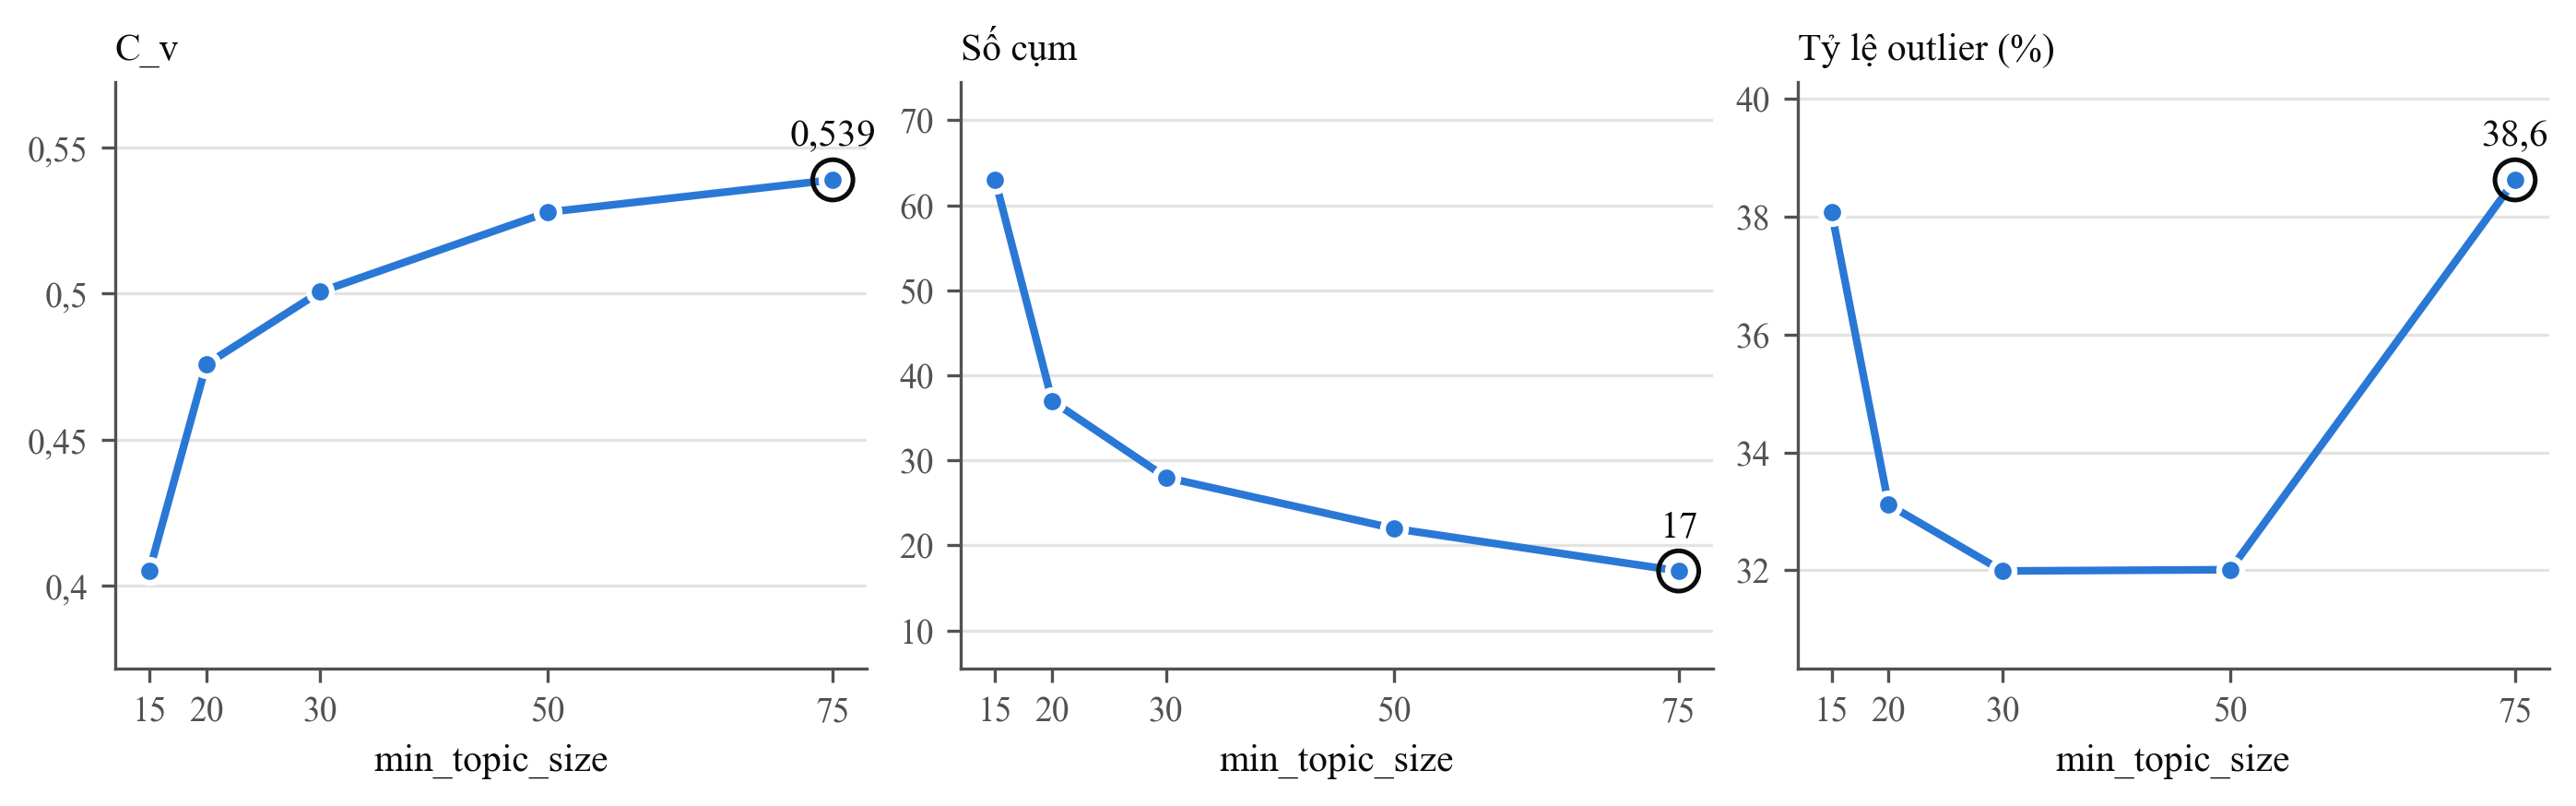

fig_gd12_2_doc_map.png


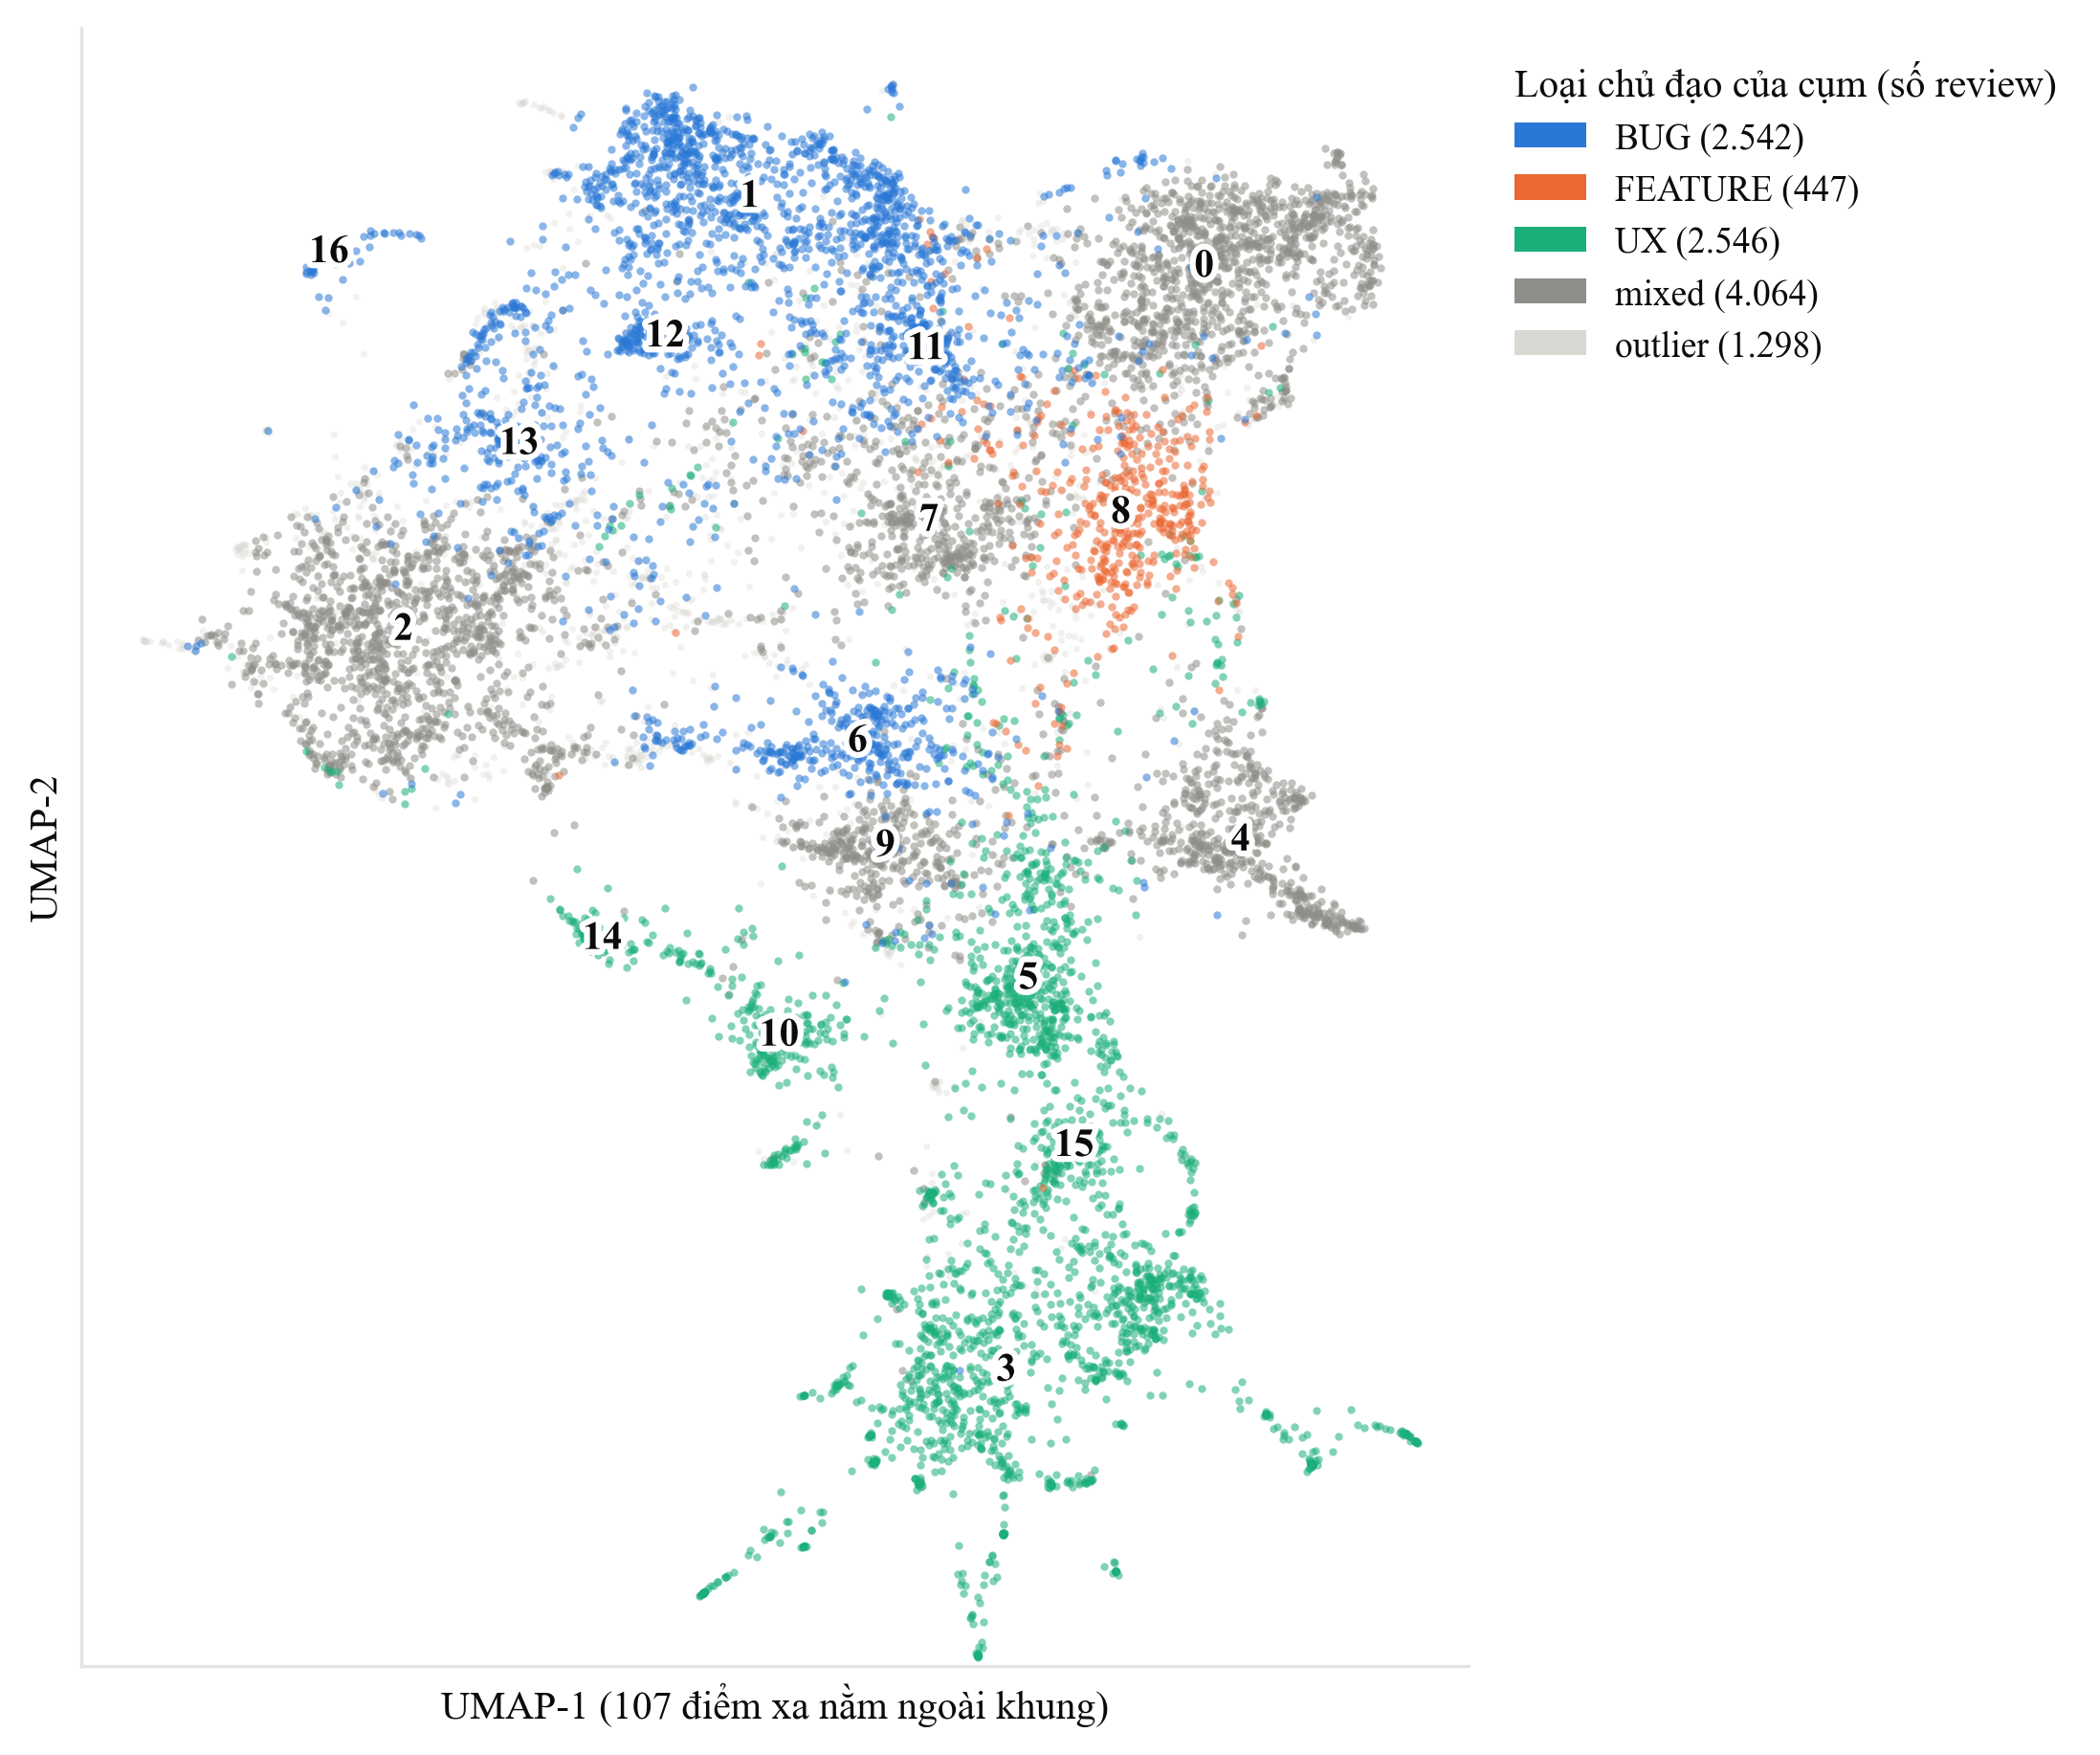

fig_gd12_3_composition.png


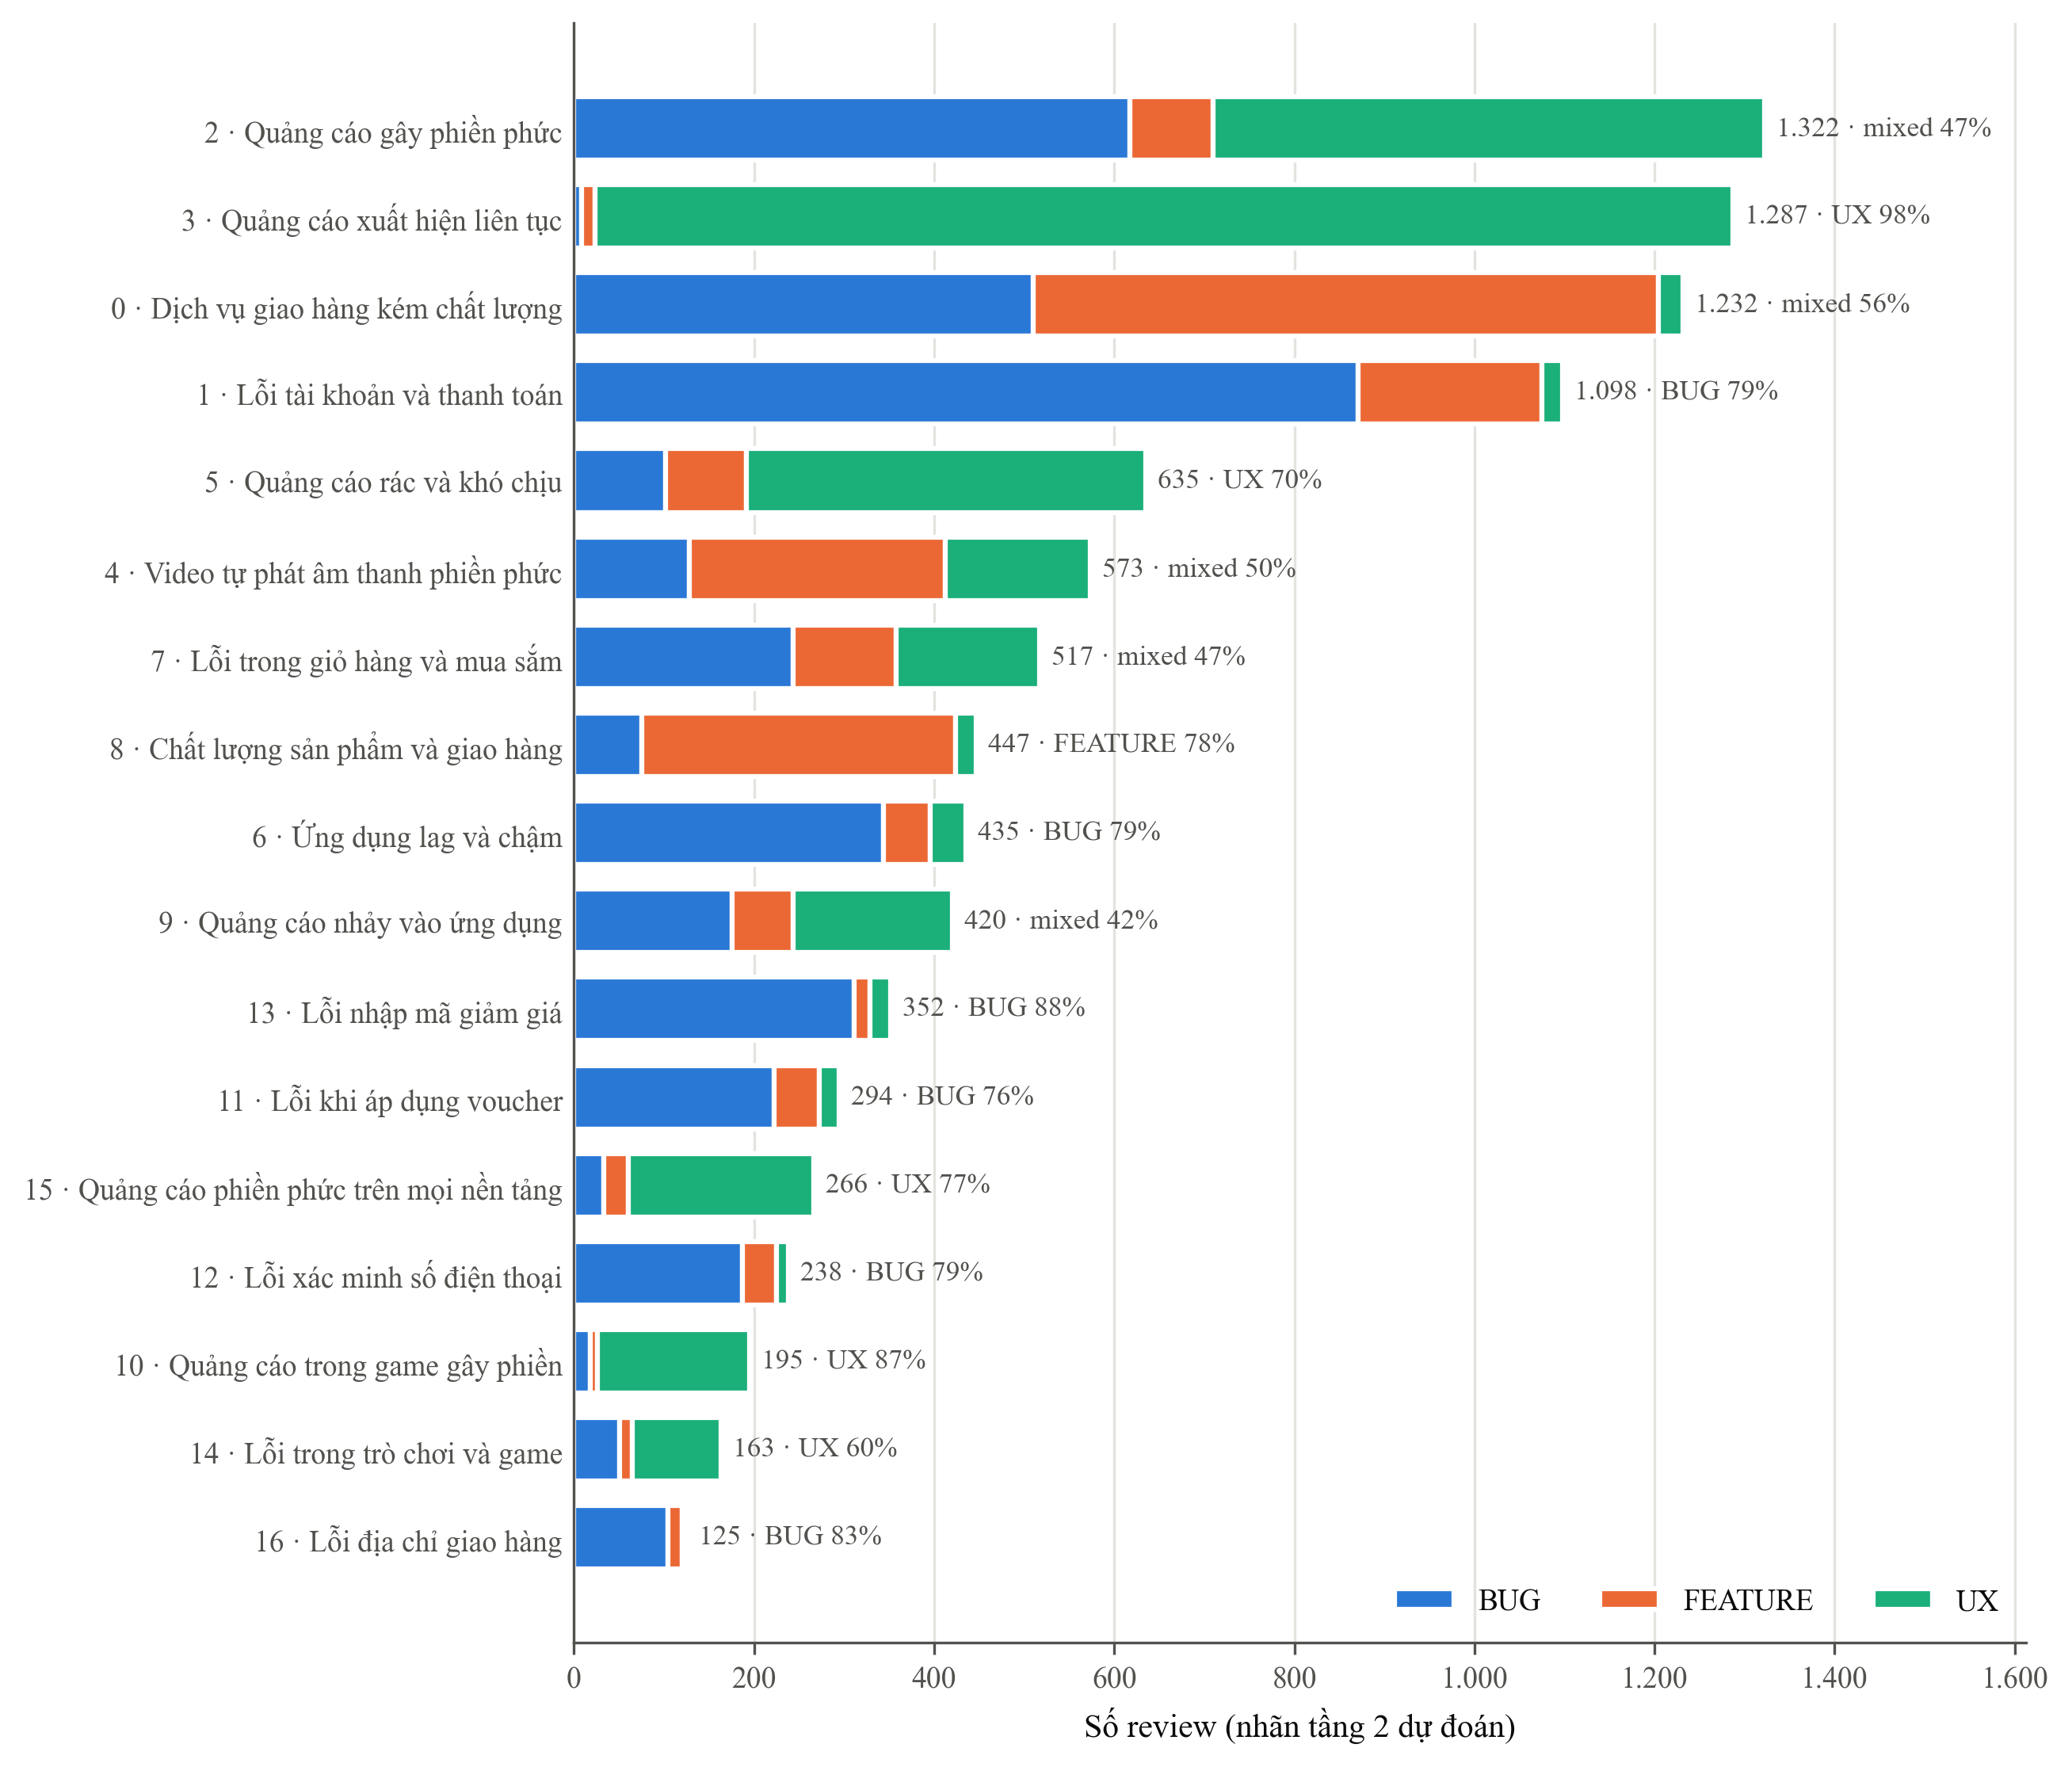

fig_gd12_4_keywords.png


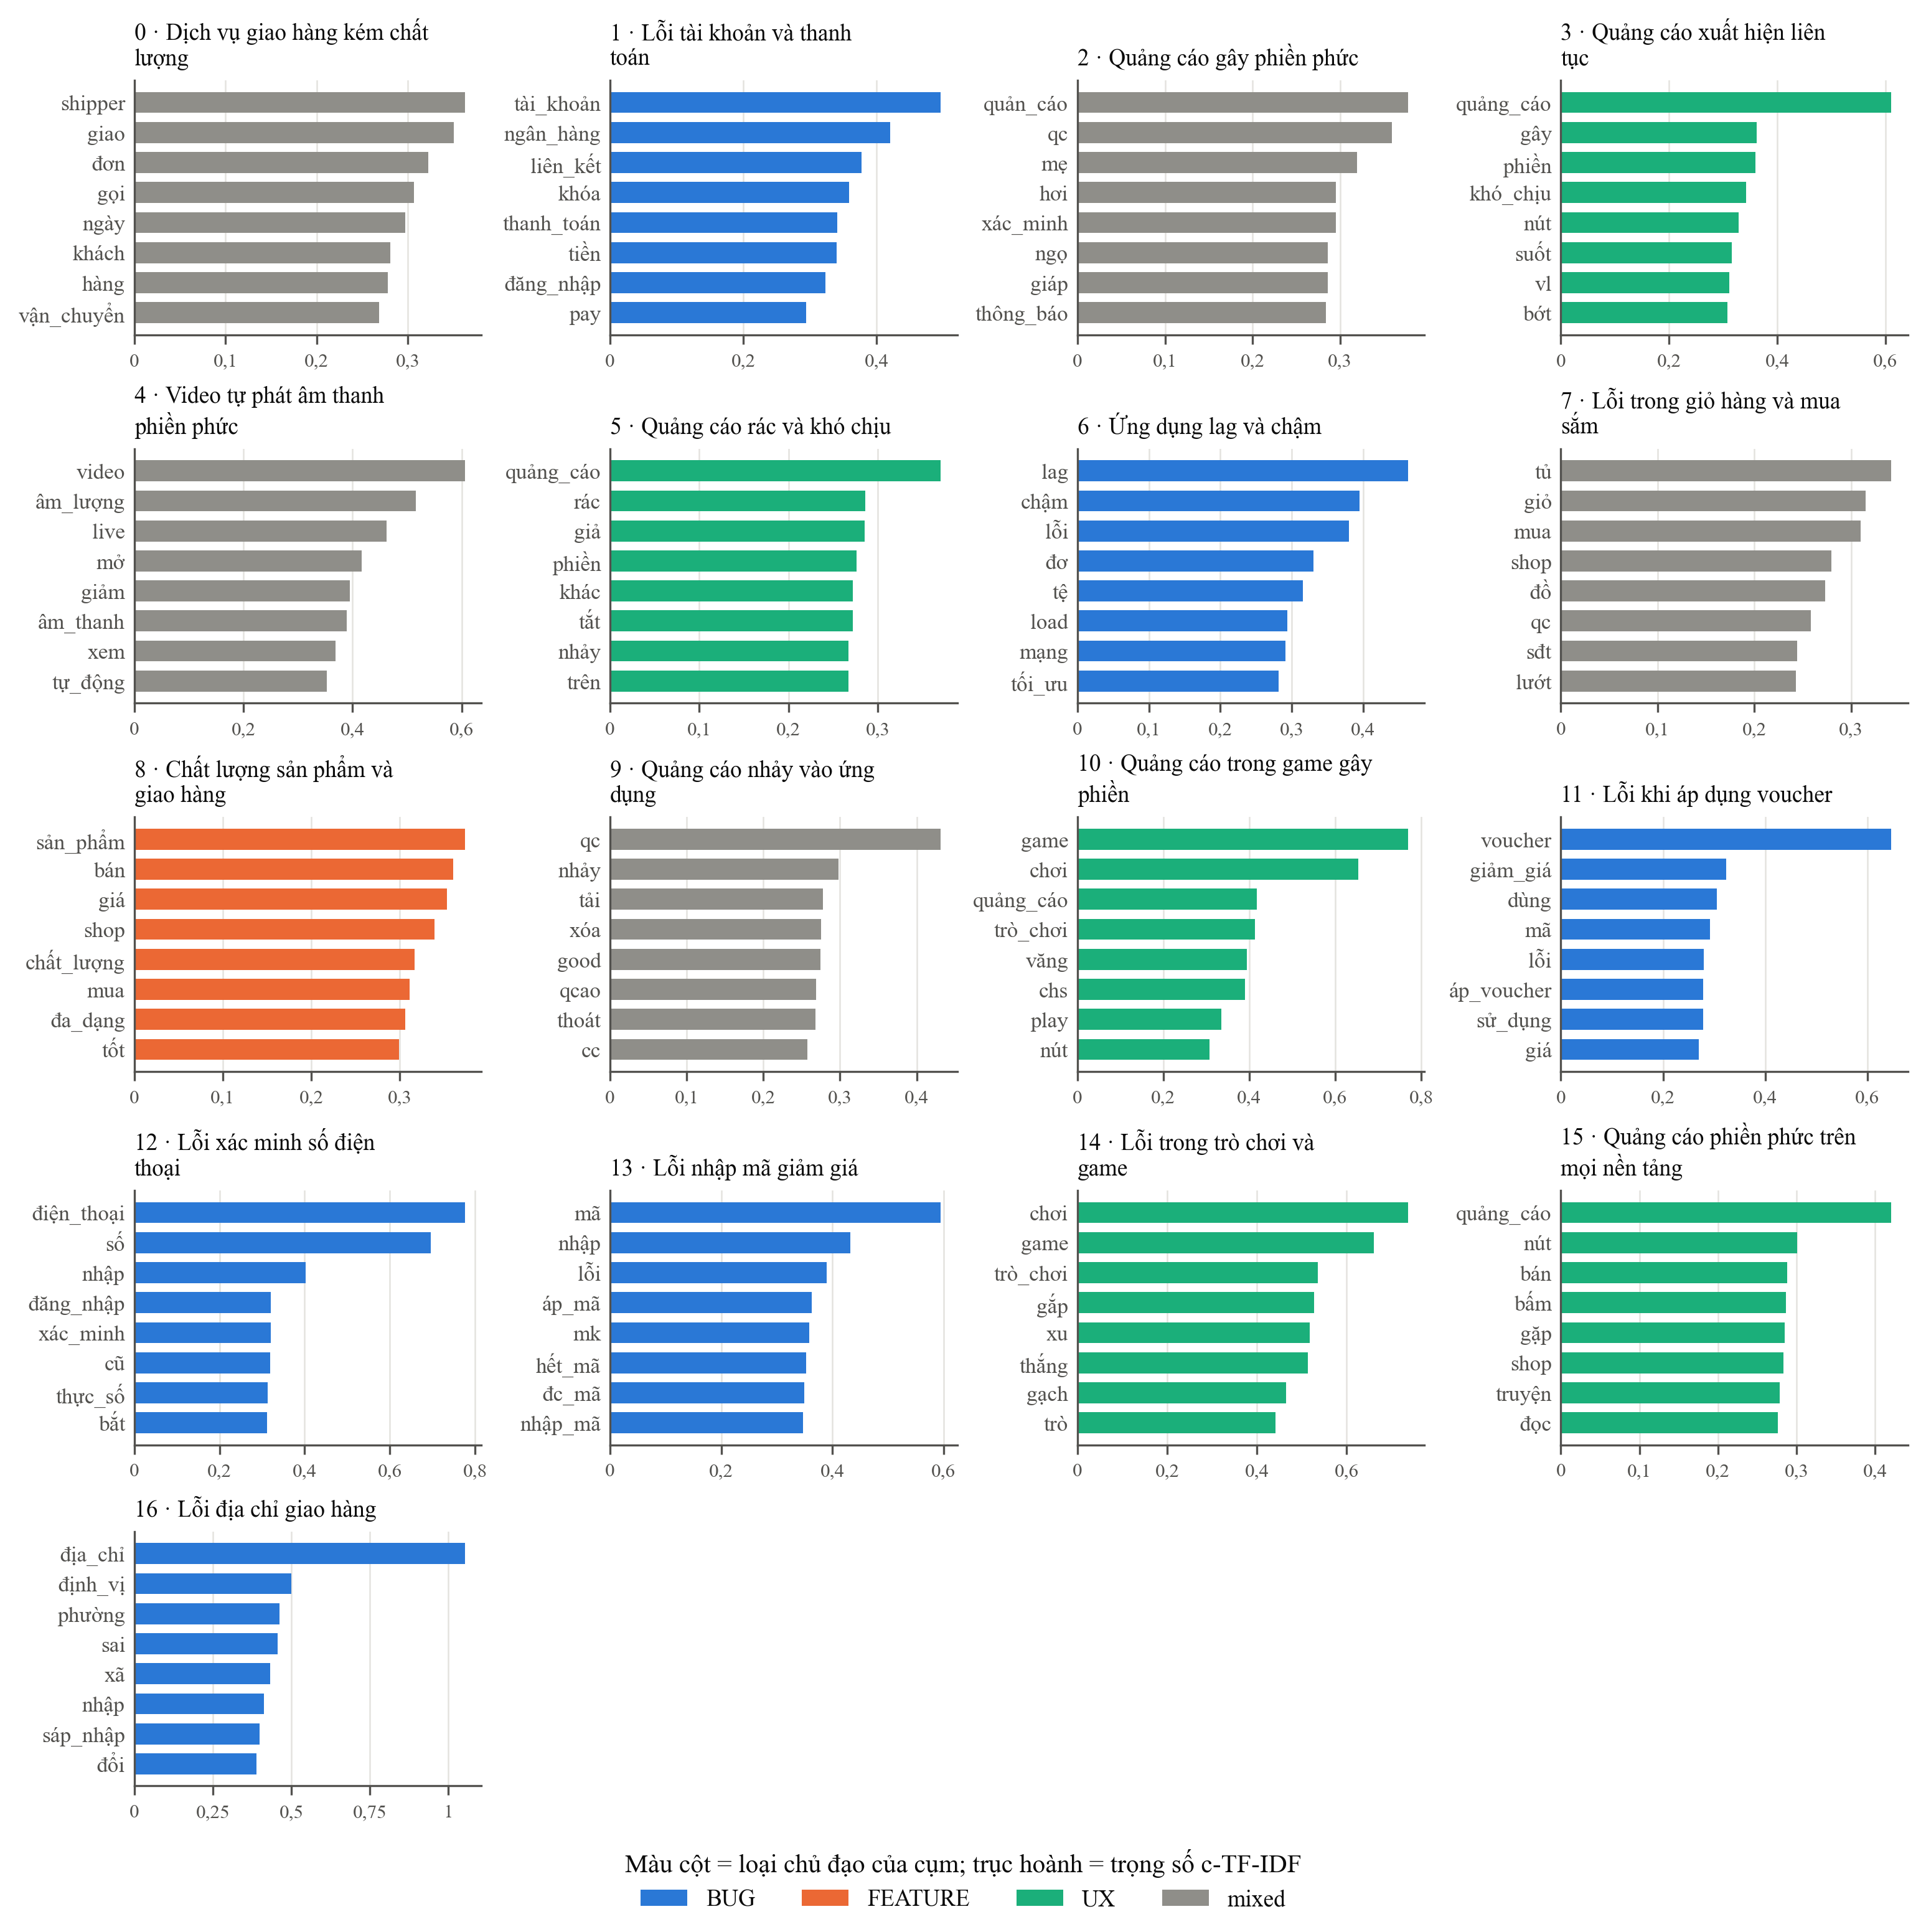

fig_gd12_5_hierarchy.png


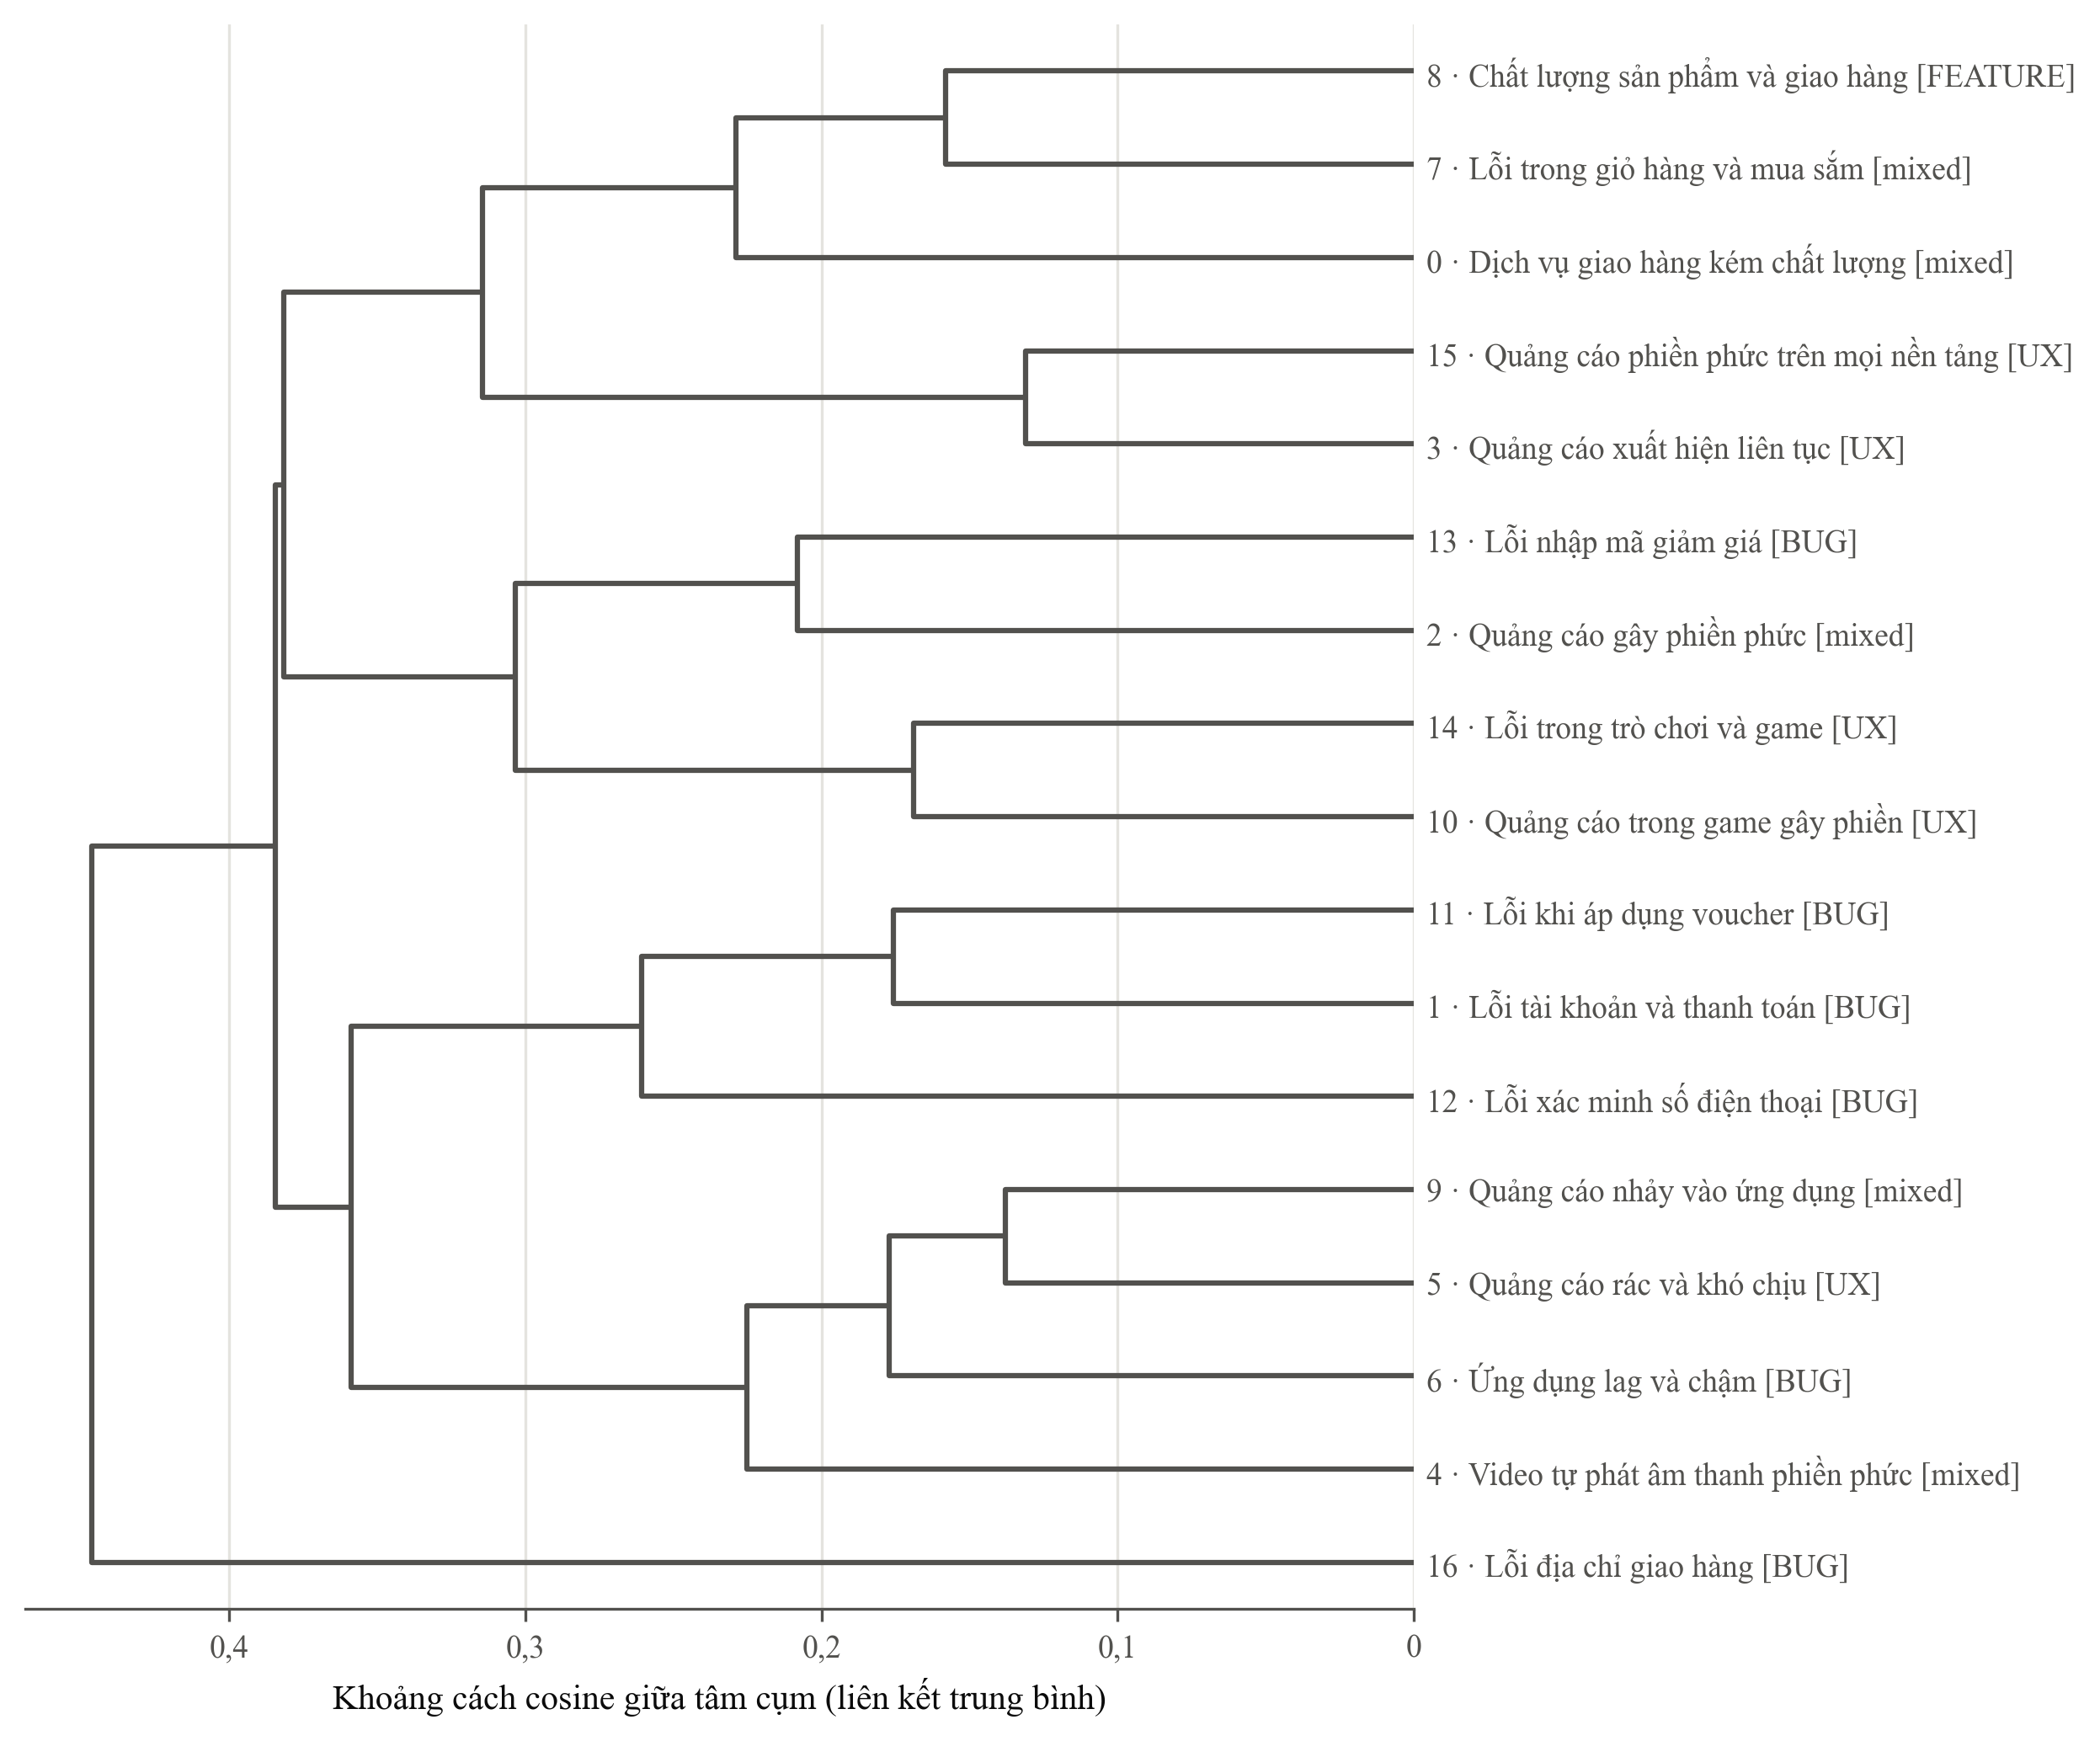

In [10]:
from src.clustering import figures as F
FIG = os.path.join(RES, 'figures')
os.makedirs(FIG, exist_ok=True)
NAMES_MAP = {int(r['topic_id']): (r['name_vi'] if isinstance(r.get('name_vi'), str) else r['keyword_name'])
             for _, r in TOPICS.iterrows() if r['topic_id'] != -1}
DOM_MAP = {int(r['topic']): r['dominant_type'] for _, r in DOM.iterrows() if r['topic'] != -1}
paths = [F.fig_grid(GRID, MTS, os.path.join(FIG, 'fig_gd12_1_grid.png')),
         F.fig_doc_map(EMB, T2, DOM_MAP, os.path.join(FIG, 'fig_gd12_2_doc_map.png'))[0],
         F.fig_composition(TOPICS, NAMES_MAP, os.path.join(FIG, 'fig_gd12_3_composition.png')),
         F.fig_keywords({t: MODEL.get_topic(t) for t in DOM_MAP}, NAMES_MAP, DOM_MAP, os.path.join(FIG, 'fig_gd12_4_keywords.png')),
         F.fig_hierarchy(EMB, T2, NAMES_MAP, DOM_MAP, os.path.join(FIG, 'fig_gd12_5_hierarchy.png'))]
from IPython.display import Image, display
for p in paths:
    print(os.path.basename(p)); display(Image(filename=p, width=900))

## Nhận xét

**Chưa viết**

Phần nhận xét được viết sau khi duyệt cụm bằng mắt; cấu hình chỉ được khóa sang `03_configs/frozen/` sau bước duyệt đó.